## Amazon Sales Data Analysis and EDA

Importing libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Uploading files

In [ ]:
from google.colab import files
files.upload()
df = pd.read_csv("messy_amazon_sales_47k.csv")

Saving messy_amazon_sales_47k.csv to messy_amazon_sales_47k.csv


data overview

In [ ]:
df.shape

(47000, 16)

In [ ]:
df.head()

,index,Order ID,Date,Status,Fulfilment,ship-service-level,Category,Size,Qty,Amount,ship-city,ship-state,ship-postal-code,B2B,promotion-ids,Unnamed: 22
0,0,401-5114137-6731941,04/05/2022,Shipped - Delivered to Buyer,Merchant,Standard,Set,3XL,1,1292.0,CHENNAI,Tamil Nadu,180734.0,False,IN Core Free Shipping 2015/04/08 23-48-5-108,NaN
1,1,408-4920197-1565132,17/06/2022,SHIPPED,Amazon,Standard,Kurta,XL,2,2196.0,Madras,Tamil Nadu,513762.0,False,IN Core Free Shipping 2015/04/08 23-48-5-108,NaN
2,2,403-2657313-2250535,19/06/2022,shipped,Merchant,Standard,Set,XL,3,3732.0,NaN,Telangana,365310.0,False,NaN,NaN
3,3,404-7437612-7301686,04-07-22,Cancelled,Merchant,Expedited,Kurta,S,1,NaN,Bangalore,Karnataka,629982.0,False,NaN,NaN
4,4,402-6214892-5075266,04-09-22,Shipped,Amazon,Standard,Saree,M,3,5964.0,Calcutta,West Bengal,761313.0,False,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47000 entries, 0 to 46999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               47000 non-null  int64  
 1   Order ID            47000 non-null  object 
 2   Date                47000 non-null  object 
 3   Status              47000 non-null  object 
 4   Fulfilment          47000 non-null  object 
 5   ship-service-level  47000 non-null  object 
 6   Category            45582 non-null  object 
 7   Size                47000 non-null  object 
 8   Qty                 47000 non-null  int64  
 9   Amount              43084 non-null  float64
 10  ship-city           45880 non-null  object 
 11  ship-state          47000 non-null  object 
 12  ship-postal-code    46142 non-null  float64
 13  B2B                 47000 non-null  bool   
 14  promotion-ids       21107 non-null  object 
 15  Unnamed: 22         0 non-null      float64
dtypes: b

In [ ]:
df.describe()

,index,Qty,Amount,ship-postal-code,Unnamed: 22
count,47000.000000,47000.000000,43084.000000,46142.000000,0.0
mean,23499.500000,1.401064,1633.625429,455854.264726,NaN
std,13567.875663,0.821734,3177.355051,199491.413125,NaN
min,0.000000,-1.000000,249.000000,110012.000000,NaN
25%,11749.750000,1.000000,746.000000,282947.250000,NaN
50%,23499.500000,1.000000,1169.000000,456260.000000,NaN
75%,35249.250000,2.000000,1833.000000,628514.500000,NaN
max,46999.000000,3.000000,59952.000000,799997.000000,NaN


In [ ]:
df.isnull().sum()

,0
index,0
Order ID,0
Date,0
Status,0
Fulfilment,0
ship-service-level,0
Category,1418
Size,0
Qty,0
Amount,3916


Deleting unwanted column

In [ ]:
df = df.drop(columns=["index", "Unnamed: 22"])

corrections

In [ ]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace("-", "_").str.replace(" ", "_"))


In [ ]:
print(df.columns.tolist())

['order_id', 'date', 'status', 'fulfilment', 'ship_service_level', 'category', 'size', 'qty', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'b2b', 'promotion_ids']


removing duplicates

In [ ]:
print("Duplicates:", df.duplicated().sum())   # ~600
df = df.drop_duplicates().reset_index(drop=True)

Duplicates: 600


In [ ]:
df.shape

(46400, 14)

fixing date columns

In [ ]:
d1 = pd.to_datetime(df["date"], format="%m-%d-%y", errors="coerce")
d2 = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="coerce")
d3 = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")

df["date"] = d1.fillna(d2).fillna(d3)

print(df["date"].isnull().sum())
print(df["date"].min(), df["date"].max())

0
2022-03-31 00:00:00 2022-06-30 00:00:00


In [ ]:
print(df["status"].value_counts())

df["status"] = df["status"].str.strip().str.lower()
df["status"] = df["status"].str.title()
print(df["status"].value_counts())

status
Shipped                         16279
Shipped - Delivered to Buyer    13929
Cancelled                        5511
shipped                          2345
Shipped - Returned to Seller     2315
Shipped - Rejected by Buyer      2254
SHIPPED                          1903
Pending                          1864
Name: count, dtype: int64
status
Shipped                         20527
Shipped - Delivered To Buyer    13929
Cancelled                        5511
Shipped - Returned To Seller     2315
Shipped - Rejected By Buyer      2254
Pending                          1864
Name: count, dtype: int64


In [ ]:
df["ship_city"] = df["ship_city"].str.strip().str.title()

df["ship_city"] = df["ship_city"].replace({
    "Bangalore": "Bengaluru",
    "Madras": "Chennai",
    "Bombay": "Mumbai",
    "Calcutta": "Kolkata",
    "New Delhi": "Delhi"
})
print(df["ship_city"].value_counts())

ship_city
Bengaluru     9107
Mumbai        8172
Chennai       6696
Delhi         6356
Hyderabad     5546
Pune          4597
Coimbatore    2627
Kolkata       2199
Name: count, dtype: int64


handling missing values

In [ ]:
print(df[df["amount"].isnull()]["status"].value_counts())

status
Cancelled    3854
Name: count, dtype: int64


In [ ]:
df["amount"] = df["amount"].fillna(0)


df["category"] = df["category"].fillna("Unknown")
df["ship_city"] = df["ship_city"].fillna("Unknown")


df["has_promo"] = df["promotion_ids"].notnull()
df = df.drop(columns=["promotion_ids"])

print(df.isnull().sum())

order_id                0
date                    0
status                  0
fulfilment              0
ship_service_level      0
category                0
size                    0
qty                     0
amount                  0
ship_city               0
ship_state              0
ship_postal_code      850
b2b                     0
has_promo               0
dtype: int64


postal code fix

In [ ]:
df["ship_postal_code"] = df["ship_postal_code"].astype("Int64").astype("string")

invalid qty remove

In [ ]:
print(df[df["qty"] < 0].shape)
df = df[df["qty"] >= 0]

(75, 14)


outliers

count    46325.000000
mean      1496.909207
std       3059.005969
min          0.000000
25%        653.000000
50%       1084.000000
75%       1759.000000
max      59952.000000
Name: amount, dtype: float64


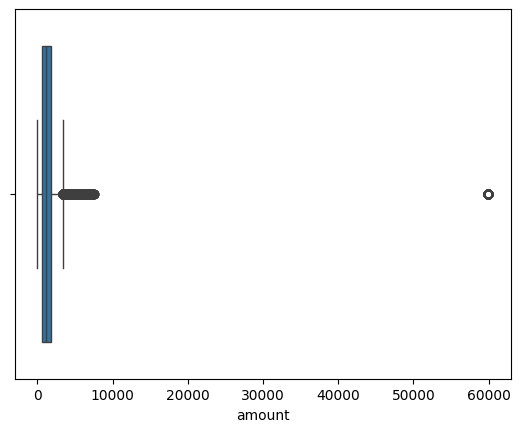

In [ ]:
print(df["amount"].describe())

sns.boxplot(x=df["amount"])
plt.show()

In [ ]:
print(df[df["amount"] > 10000].shape)
df = df[df["amount"] <= 10000]

(110, 14)


cheking datatypes

In [ ]:
df["b2b"] = df["b2b"].astype(bool)
for col in ["status", "category", "size", "fulfilment", "ship_service_level", "ship_state"]:
    df[col] = df[col].astype("category")
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 46215 entries, 0 to 46399
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            46215 non-null  object        
 1   date                46215 non-null  datetime64[ns]
 2   status              46215 non-null  category      
 3   fulfilment          46215 non-null  category      
 4   ship_service_level  46215 non-null  category      
 5   category            46215 non-null  category      
 6   size                46215 non-null  category      
 7   qty                 46215 non-null  int64         
 8   amount              46215 non-null  float64       
 9   ship_city           46215 non-null  object        
 10  ship_state          46215 non-null  category      
 11  ship_postal_code    45368 non-null  string        
 12  b2b                 46215 non-null  bool          
 13  has_promo           46215 non-null  bool          


new features

In [ ]:
df["month"] = df["date"].dt.month_name()
df["day_of_week"] = df["date"].dt.day_name()
df["is_cancelled"] = df["status"].str.contains("Cancel")
df["revenue"] = np.where(df["is_cancelled"], 0, df["amount"])

final validation

In [ ]:
print(df.shape)
print(df.isnull().sum())
print(df.duplicated().sum())
df.head()

(46215, 18)
order_id                0
date                    0
status                  0
fulfilment              0
ship_service_level      0
category                0
size                    0
qty                     0
amount                  0
ship_city               0
ship_state              0
ship_postal_code      847
b2b                     0
has_promo               0
month                   0
day_of_week             0
is_cancelled            0
revenue                 0
dtype: int64
0


,order_id,date,status,fulfilment,ship_service_level,category,size,qty,amount,ship_city,ship_state,ship_postal_code,b2b,has_promo,month,day_of_week,is_cancelled,revenue
0,401-5114137-6731941,2022-05-04,Shipped - Delivered To Buyer,Merchant,Standard,Set,3XL,1,1292.0,Chennai,Tamil Nadu,180734,False,True,May,Wednesday,False,1292.0
1,408-4920197-1565132,2022-06-17,Shipped,Amazon,Standard,Kurta,XL,2,2196.0,Chennai,Tamil Nadu,513762,False,True,June,Friday,False,2196.0
2,403-2657313-2250535,2022-06-19,Shipped,Merchant,Standard,Set,XL,3,3732.0,Unknown,Telangana,365310,False,False,June,Sunday,False,3732.0
3,404-7437612-7301686,2022-04-07,Cancelled,Merchant,Expedited,Kurta,S,1,0.0,Bengaluru,Karnataka,629982,False,False,April,Thursday,True,0.0
4,402-6214892-5075266,2022-04-09,Shipped,Amazon,Standard,Saree,M,3,5964.0,Kolkata,West Bengal,761313,False,False,April,Saturday,False,5964.0


In [ ]:
df.to_csv("cleaned_amazon_sales.csv", index=False)
files.download("cleaned_amazon_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

EDA

In [ ]:
print(df.shape)
df.describe()
df.describe(include="category")

(46215, 18)


,status,fulfilment,ship_service_level,category,size,ship_state
count,46215,46215,46215,46215,46215,46215
unique,6,2,2,7,7,6
top,Shipped,Amazon,Standard,Kurta,L,Maharashtra
freq,20433,32483,30252,12578,9297,13052


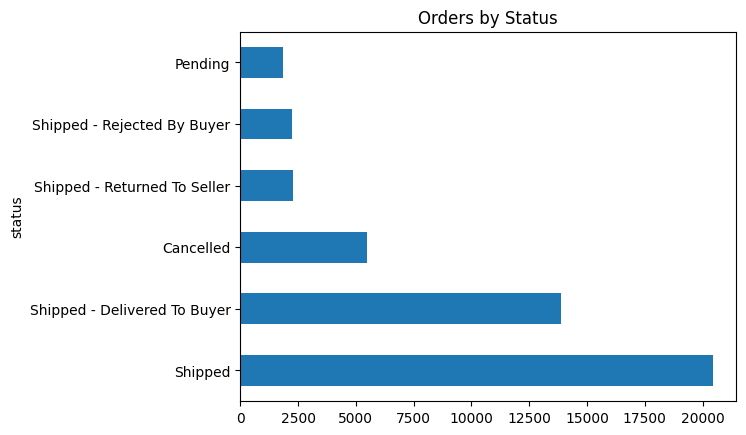

In [ ]:
df["status"].value_counts()
df["status"].value_counts().plot(kind="barh", title="Orders by Status")
plt.show()

CANCELLATION RETURN DATE

In [ ]:
df["is_returned"] = df["status"].str.contains("Returned|Rejected")
print("Cancel %:", round(df["is_cancelled"].mean()*100, 2))
print("Return %:", round(df["is_returned"].mean()*100, 2))

Cancel %: 11.89
Return %: 9.84


Category analysis

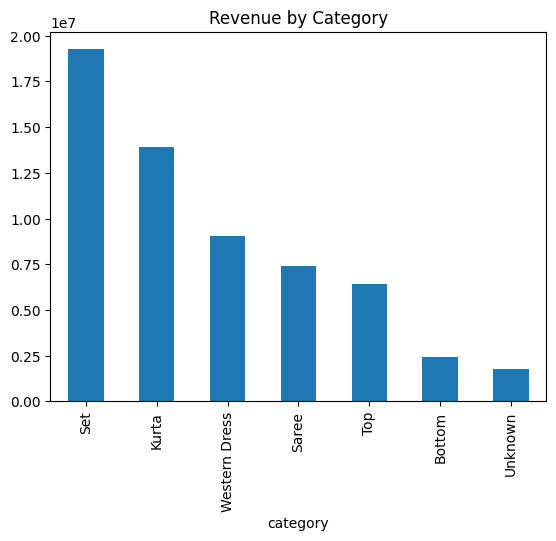

In [ ]:
cat = df.groupby("category", observed=True).agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    cancel_rate=("is_cancelled", "mean")
).sort_values("revenue", ascending=False)
cat["cancel_rate"] = (cat["cancel_rate"]*100).round(1)
cat

cat["revenue"].plot(kind="bar", title="Revenue by Category")
plt.show()

size analysis

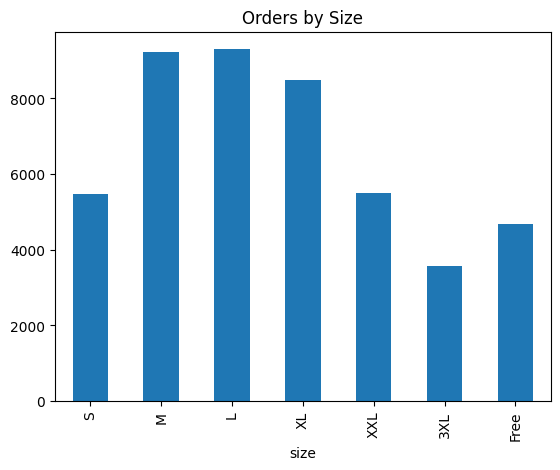

In [ ]:
size_order = ["S","M","L","XL","XXL","3XL","Free"]
df["size"].value_counts().reindex(size_order).plot(kind="bar", title="Orders by Size")
plt.show()

City abd State Analysis

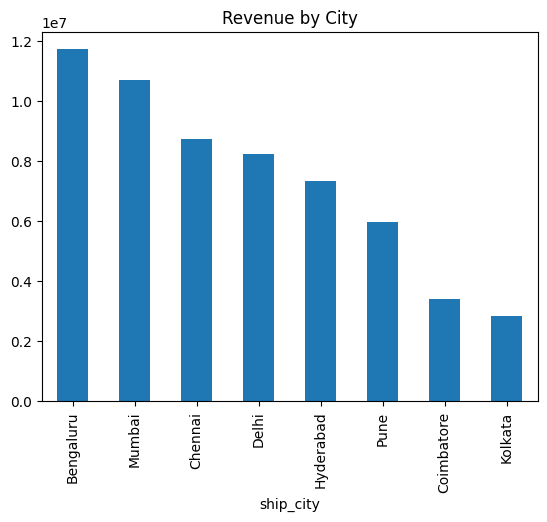

,revenue
ship_state,
Maharashtra,17106143.0
Tamil Nadu,12415481.0
Karnataka,11978798.0
Delhi,8431117.0
Telangana,7514573.0
West Bengal,2907459.0


In [ ]:
city = (df[df["ship_city"] != "Unknown"]
        .groupby("ship_city")["revenue"].sum().sort_values(ascending=False))
city.plot(kind="bar", title="Revenue by City")
plt.show()

df.groupby("ship_state", observed=True)["revenue"].sum().sort_values(ascending=False)

fullfilment comparison

In [ ]:
f = df.groupby("fulfilment", observed=True).agg(
    orders=("order_id", "count"),
    cancel_rate=("is_cancelled", "mean"),
    return_rate=("is_returned", "mean"))
(f[["cancel_rate","return_rate"]]*100).round(2)

,cancel_rate,return_rate
fulfilment,,
Amazon,11.96,9.96
Merchant,11.71,9.55


promotion effect

In [ ]:
promo = df[~df["is_cancelled"]].groupby("has_promo")["amount"].agg(["count","mean"])
promo

,count,mean
has_promo,,
False,22381,1488.285599
True,18341,1474.524344


time trend

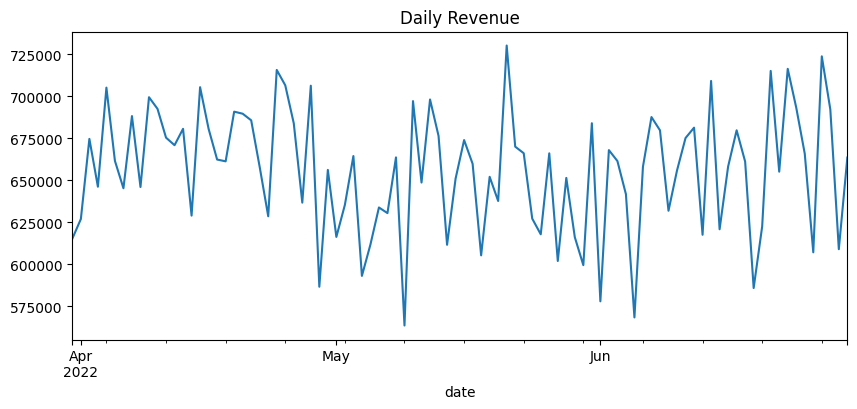

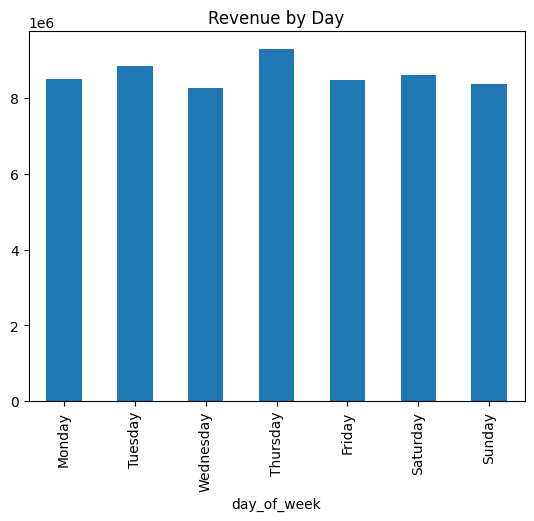

In [ ]:
df.groupby("date")["revenue"].sum().plot(figsize=(10,4), title="Daily Revenue")
plt.show()

order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df.groupby("day_of_week")["revenue"].sum().reindex(order).plot(kind="bar", title="Revenue by Day")
plt.show()

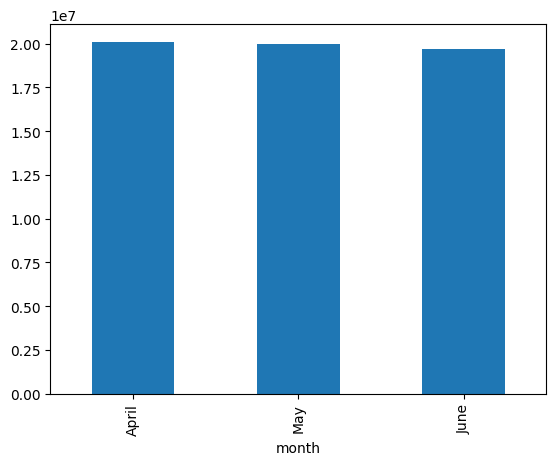

In [ ]:
m = df[df["date"] >= "2022-04-01"]
m.groupby("month")["revenue"].sum().reindex(["April","May","June"]).plot(kind="bar")
plt.show()

distribution of amount

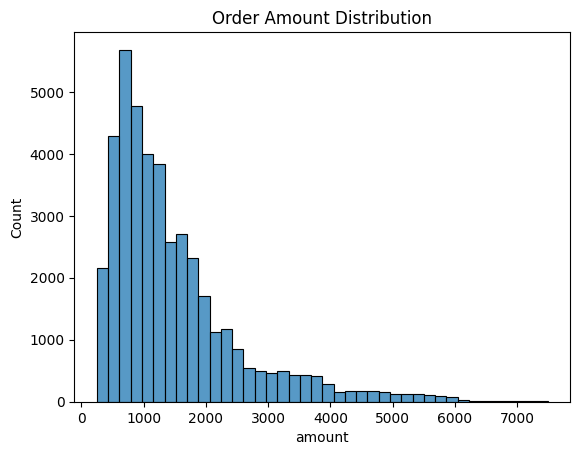

In [ ]:
sns.histplot(df[df["amount"] > 0]["amount"], bins=40)
plt.title("Order Amount Distribution")
plt.show()

category X city heatmap

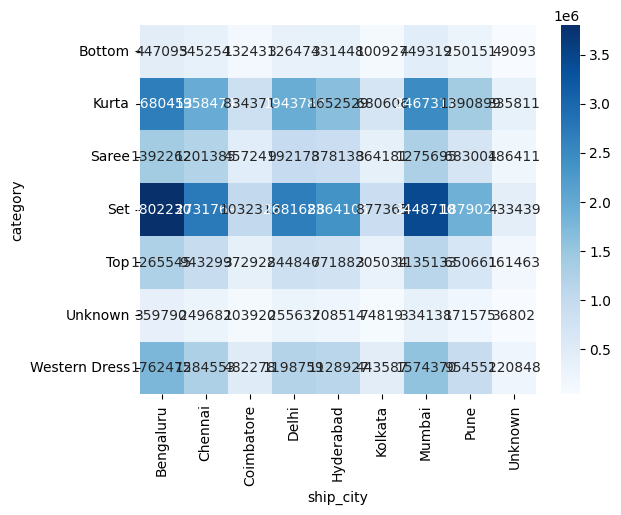

In [ ]:
pivot = df.pivot_table(index="category", columns="ship_city",
                       values="revenue", aggfunc="sum", observed=True)
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues")
plt.show()

correlation

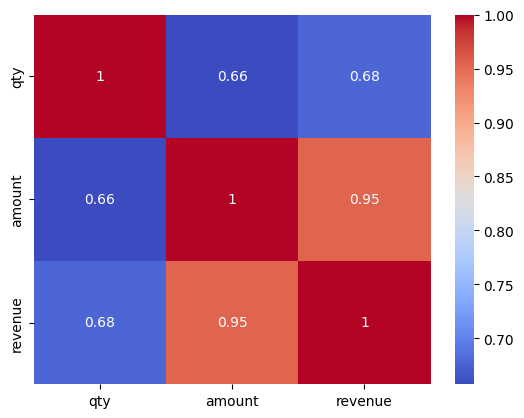

In [ ]:
sns.heatmap(df[["qty","amount","revenue"]].corr(), annot=True, cmap="coolwarm")
plt.show()